In [1]:
import lsst.daf.butler as dafButler
from lsst.summit.utils.utils import getCameraFromInstrumentName

import numpy as np


from astropy.time import Time
from astropy.coordinates import EarthLocation, SkyCoord, AltAz 
from astropy import units as u
from astroquery.vizier import Vizier
from skyfield.api import load



import lsst_efd_client
import matplotlib.pyplot as plt
%matplotlib inline
%matplotlib widget

In [2]:
def get_moon_position(mjd):
    
    # Input time in MJD
    time_astropy = Time(mjd, format='mjd')
    ts = load.timescale()
    time = ts.tdb(jd=time_astropy.jd)

    # Load ephemeris
    eph = load('de440s.bsp')  # or 'de440s.bsp' for more precision

    # Observer (optional: for topocentric correction)
    earth = eph['earth']
    moon = eph['moon']

    # Get position of the Moon from Earth's center (geocentric)
    moon_position = earth.at(time).observe(moon).apparent()
    ra_moon, dec_moon, _ = moon_position.radec()

    ra_deg = ra_moon.hours * 15  # Convert hours to degrees
    dec_deg = dec_moon.degrees  # Already in degrees

    # Moon's position as SkyCoord
    moon_coord = SkyCoord(ra=ra_deg * u.deg, dec=dec_deg * u.deg, frame='icrs')

    return moon_coord

def convert_radec_to_altaz(loc, t, radecCoord):
    if not isinstance(t, Time):
        t = Time(t)
    
    loc = EarthLocation.of_site(loc)
    altaz = AltAz(location=loc, obstime=t)
    radecCoord = SkyCoord(radecCoord)
    return radecCoord.transform_to(altaz)
    
def find_bright_stars(center, max_dist, mag_filter_dict = {"Vmag": "<2.5"}):

    vizier = Vizier(columns=["*"] + [cols for cols in mag_filter_dict.keys()], column_filters=mag_filter_dict)
    vizier.ROW_LIMIT = -1

    # Query sul catalogo Hipparcos piu leggero tanto mi interessano solo le stelle piu brillanti che ci sono anche qua
    result = vizier.query_region(center, radius=max_dist, catalog="I/239/hip_main")
    
    if len(result) == 0:
        print("No stars found in the specified region.")
        return None

    stars = result[0][['HIP', 'Vmag', '_RA.icrs', '_DE.icrs']]
    stars.sort("Vmag")

    if len(stars) > 5:
        print(f"Found {len(result[0])} stars in the specified region. Limiting to 3 brightest stars.")
        stars = stars[:5]
    
    return stars

def get_alt_ha(target, center, loc, tobs):
    
    d = target.separation(center).deg
    target_altaz = convert_radec_to_altaz(loc, tobs, target)
    center_altaz = convert_radec_to_altaz(loc, tobs, center)
    
    delta_alt = center_altaz.alt.deg - target_altaz.alt.deg 
    return np.rad2deg(np.asin(delta_alt / d))

In [3]:
# butler = dafButler.Butler("embargo", collections=["LSSTCam/runs/nightlyValidation", "u/ataranto/lsst_outputs"], instrument="LSSTCam")
butler = dafButler.Butler("embargo", collections=["u/ataranto/lsst_outputs"], instrument="LSSTCam")
camera = getCameraFromInstrumentName("LSSTCam")
# Get the EFD client
client = lsst_efd_client.EfdClient("usdf_efd")

In [4]:
visits=range()

In [5]:
frames = []
alpha_cen_alts = []
alpha_cen_azs = []
ti = butler.get("raw.visitInfo", exposure=visits[0], detector=94).date.toAstropy()
max_dist =30 * u.deg

for visit in visits:
    print(f'Processing visit {visit}')
    # visit info
    t = butler.get("raw.visitInfo", exposure=visit, detector=94).date.toAstropy()
    rot_angle = butler.get("raw.visitInfo", exposure=visit, detector=94).boresightRotAngle.asDegrees()
    band = butler.get("raw.filter", exposure=visits[0], detector=94).bandLabel

    ra = butler.get("raw.visitInfo", exposure=visit, detector=94).boresightRaDec.getRa().asDegrees()
    dec = butler.get("raw.visitInfo", exposure=visit, detector=94).boresightRaDec.getDec().asDegrees()
    center = SkyCoord(ra=ra, dec=dec, unit=(u.deg, u.deg), frame='icrs')

    # bright stars
    brightest_stars = find_bright_stars(center, max_dist, mag_filter_dict={"Vmag": "<3"})

    if brightest_stars is not None:
        stars_legend = []
        for i, star in enumerate(brightest_stars):
            starCoord = SkyCoord(ra=star['_RA.icrs'], dec=star['_DE.icrs'], unit=(u.deg, u.deg), frame='icrs')
            starDistance = center.separation(starCoord).deg
            starVMag = star['Vmag']
            star_ha = get_alt_ha(starCoord, center, "rubin", t)
            print(f"\t{i+1} - HIP {int(star['HIP'])}, Vmag: {starVMag:.2f}, at {starDistance:.3f}°, TEA HA: {star_ha:.1f}°")
 
    # retrieve moon position
    moon = get_moon_position(t.mjd)
    moonDistance = center.separation(moon).deg
    moon_ha = get_alt_ha(moon, center, "rubin", t)
    print(f"Moon distance: {moonDistance:.2f}°, TEA HA: {moon_ha:.1f}")
    # Convert center (ra, dec) to AltAz
    center_altaz = convert_radec_to_altaz("rubin", t, center)
    # Alpha Centauri coordinates (J2000): RA=219.90205833 deg, Dec=-60.8339925 deg
    alpha_cen_icrs = SkyCoord(ra=219.90205833 * u.deg, dec=-60.8339925 * u.deg, frame='icrs')
    alpha_cen_altaz = convert_radec_to_altaz("rubin", t, alpha_cen_icrs)

    # Store Alpha Centauri alt-az for plotting

    alpha_cen_alts.append(alpha_cen_altaz.alt.deg)
    alpha_cen_azs.append(alpha_cen_altaz.az.deg)
    # Store results for plotting
    frames.append({
        "visit": visit,
        "ra": ra,
        "dec": dec,
        "alt": center_altaz.alt.deg,
        "az": center_altaz.az.deg
    })

    # After the loop, plot all points
    

Processing visit 2025060800335
Found 25 stars in the specified region. Limiting to 3 brightest stars.
	1 - HIP 71683, Vmag: -0.01, at 2.920°, TEA HA: 89.1°
	2 - HIP 68702, Vmag: 0.61, at 6.776°, TEA HA: 65.1°
	3 - HIP 60718, Vmag: 0.77, at 18.365°, TEA HA: 76.0°
	4 - HIP 62434, Vmag: 1.25, at 16.262°, TEA HA: 65.2°
	5 - HIP 71681, Vmag: 1.35, at 2.924°, TEA HA: 89.1°
Moon distance: 35.98°, TEA HA: -24.4
Processing visit 2025060800336
Found 25 stars in the specified region. Limiting to 3 brightest stars.
	1 - HIP 71683, Vmag: -0.01, at 2.937°, TEA HA: 88.8°
	2 - HIP 68702, Vmag: 0.61, at 6.792°, TEA HA: 65.4°
	3 - HIP 60718, Vmag: 0.77, at 18.382°, TEA HA: 76.2°
	4 - HIP 62434, Vmag: 1.25, at 16.277°, TEA HA: 65.5°
	5 - HIP 71681, Vmag: 1.35, at 2.941°, TEA HA: 88.8°
Moon distance: 35.97°, TEA HA: -24.3
Processing visit 2025060800337
Found 25 stars in the specified region. Limiting to 3 brightest stars.
	1 - HIP 71683, Vmag: -0.01, at 2.954°, TEA HA: 88.6°
	2 - HIP 68702, Vmag: 0.61, at

/lscratch/ataranto/ipykernel_3552630/4187226854.py:64: RuntimeWarning: invalid value encountered in arcsin
  return np.rad2deg(np.asin(delta_alt / d))


Found 25 stars in the specified region. Limiting to 3 brightest stars.
	1 - HIP 71683, Vmag: -0.01, at 4.027°, TEA HA: 77.2°
	2 - HIP 68702, Vmag: 0.61, at 7.885°, TEA HA: 82.0°
	3 - HIP 60718, Vmag: 0.77, at 19.497°, TEA HA: nan°
	4 - HIP 62434, Vmag: 1.25, at 17.357°, TEA HA: 79.8°
	5 - HIP 71681, Vmag: 1.35, at 4.031°, TEA HA: 77.2°
Moon distance: 35.13°, TEA HA: -14.2
Processing visit 2025060800401


/lscratch/ataranto/ipykernel_3552630/4187226854.py:64: RuntimeWarning: invalid value encountered in arcsin
  return np.rad2deg(np.asin(delta_alt / d))


Found 25 stars in the specified region. Limiting to 3 brightest stars.
	1 - HIP 71683, Vmag: -0.01, at 4.044°, TEA HA: 77.1°
	2 - HIP 68702, Vmag: 0.61, at 7.902°, TEA HA: 82.3°
	3 - HIP 60718, Vmag: 0.77, at 19.515°, TEA HA: nan°
	4 - HIP 62434, Vmag: 1.25, at 17.375°, TEA HA: 80.0°
	5 - HIP 71681, Vmag: 1.35, at 4.048°, TEA HA: 77.1°
Moon distance: 35.12°, TEA HA: -14.0
Processing visit 2025060800402


...

Found 25 stars in the specified region. Limiting to 3 brightest stars.
	1 - HIP 71683, Vmag: -0.01, at 4.060°, TEA HA: 77.0°
	2 - HIP 68702, Vmag: 0.61, at 7.920°, TEA HA: 82.5°
	3 - HIP 60718, Vmag: 0.77, at 19.533°, TEA HA: nan°
	4 - HIP 62434, Vmag: 1.25, at 17.392°, TEA HA: 80.2°
	5 - HIP 71681, Vmag: 1.35, at 4.065°, TEA HA: 77.0°
Moon distance: 35.11°, TEA HA: -13.9
Processing visit 2025060800403


/lscratch/ataranto/ipykernel_3552630/4187226854.py:64: RuntimeWarning: invalid value encountered in arcsin
  return np.rad2deg(np.asin(delta_alt / d))


Found 25 stars in the specified region. Limiting to 3 brightest stars.
	1 - HIP 71683, Vmag: -0.01, at 4.077°, TEA HA: 76.8°
	2 - HIP 68702, Vmag: 0.61, at 7.938°, TEA HA: 82.7°
	3 - HIP 60718, Vmag: 0.77, at 19.550°, TEA HA: nan°
	4 - HIP 62434, Vmag: 1.25, at 17.410°, TEA HA: 80.4°
	5 - HIP 71681, Vmag: 1.35, at 4.081°, TEA HA: 76.8°
Moon distance: 35.09°, TEA HA: -13.8
Processing visit 2025060800404


/lscratch/ataranto/ipykernel_3552630/4187226854.py:64: RuntimeWarning: invalid value encountered in arcsin
  return np.rad2deg(np.asin(delta_alt / d))


Found 25 stars in the specified region. Limiting to 3 brightest stars.
	1 - HIP 71683, Vmag: -0.01, at 4.094°, TEA HA: 76.7°
	2 - HIP 68702, Vmag: 0.61, at 7.956°, TEA HA: 82.9°
	3 - HIP 60718, Vmag: 0.77, at 19.568°, TEA HA: 89.6°
	4 - HIP 62434, Vmag: 1.25, at 17.428°, TEA HA: 80.6°
	5 - HIP 71681, Vmag: 1.35, at 4.098°, TEA HA: 76.7°
Moon distance: 35.08°, TEA HA: -13.6
Processing visit 2025060800405
Found 25 stars in the specified region. Limiting to 3 brightest stars.
	1 - HIP 71683, Vmag: -0.01, at 4.111°, TEA HA: 76.5°
	2 - HIP 68702, Vmag: 0.61, at 7.974°, TEA HA: 83.1°
	3 - HIP 60718, Vmag: 0.77, at 19.586°, TEA HA: 89.4°
	4 - HIP 62434, Vmag: 1.25, at 17.446°, TEA HA: 80.8°
	5 - HIP 71681, Vmag: 1.35, at 4.115°, TEA HA: 76.5°
Moon distance: 35.07°, TEA HA: -13.5
Processing visit 2025060800406
Found 25 stars in the specified region. Limiting to 3 brightest stars.
	1 - HIP 71683, Vmag: -0.01, at 4.128°, TEA HA: 76.4°
	2 - HIP 68702, Vmag: 0.61, at 7.991°, TEA HA: 83.4°
	3 - HIP

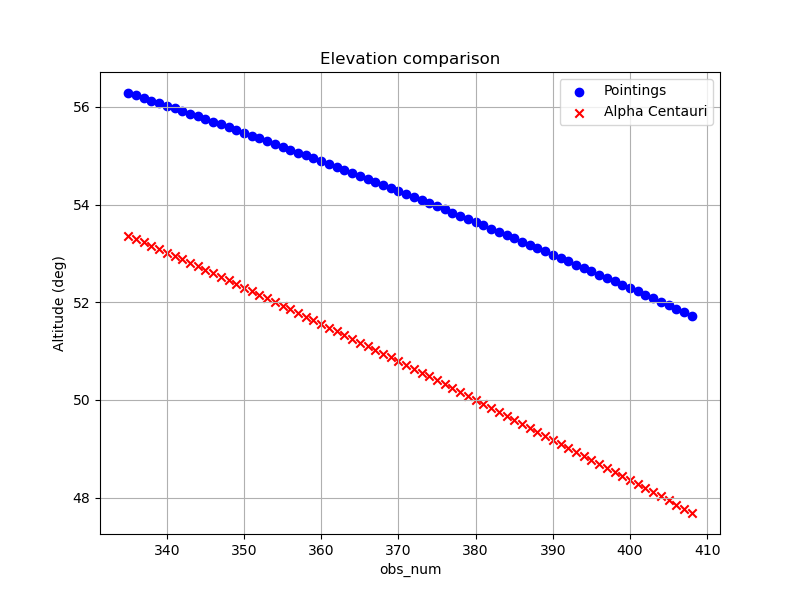

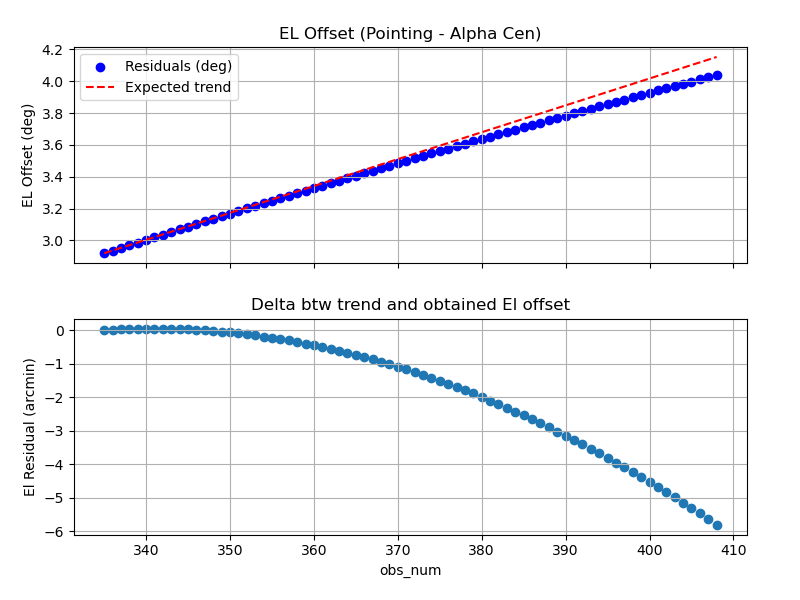

First point line: y = 33.1422 * x + -6716.2305
Last point line: y = 2.6113 * x + -501.6874


In [12]:
from numpy.polynomial.polynomial import Polynomial

import matplotlib.pyplot as plt

alts = [f["alt"] for f in frames]
azs = [f["az"] for f in frames]
ind=range(335,335+len(azs))
plt.figure(figsize=(8, 6))
plt.scatter(ind, alts, c='b', label='Pointings')
plt.scatter(ind, alpha_cen_alts, c='r', label='Alpha Centauri', marker='x')
plt.xlabel('obs_num')
plt.ylabel('Altitude (deg)')
plt.title('Elevation comparison')
plt.grid(True)
plt.legend()
plt.show()
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
fig.tight_layout(pad=3.0)

# Altitude residuals
alt_residuals = np.array(alts) - np.array(alpha_cen_alts)
ax1.scatter(ind,alt_residuals, marker='o',label='Residuals (deg)', color='blue')


# Linear fit to altitude residuals
fit_idx = np.arange(3)
fit_coef = np.polyfit(fit_idx, alt_residuals[:3], 1)
fit_line = np.polyval(fit_coef, np.arange(len(alt_residuals)))
ax1.plot(np.arange(335,335+len(alt_residuals)), fit_line, 'r--', label='Expected trend')
ax1.legend()
ax1.set_ylabel('EL Offset (deg)')
ax1.set_title('EL Offset (Pointing - Alpha Cen)')
ax1.grid(True)

# Azimuth residuals
az_residuals = np.array(azs) - np.array(alpha_cen_azs)
alt_residuals_arcmin = alt_residuals * 60
trend = np.arange(alt_residuals_arcmin[0], alt_residuals_arcmin[0] + len(alt_residuals_arcmin))
alt_residuals_arcmin_corr = alt_residuals_arcmin - trend

ax2.scatter(ind, alt_residuals_arcmin_corr, marker='o', label='Corrected (arcmin)')

# ax2.plot(az_residuals, marker='o', color='orange')
ax2.set_xlabel('obs_num')
ax2.set_ylabel('El Residual (arcmin)')
ax2.set_title('Delta btw trend and obtained El offset')
ax2.grid(True)

plt.show()


# Fit a line (degree 1 polynomial) through the first point of each array
x_first = np.array([azs[0], alpha_cen_azs[0]])
y_first = np.array([alts[0], alpha_cen_alts[0]])
p_first = Polynomial.fit(x_first, y_first, 1).convert()
print(f"First point line: y = {p_first.coef[1]:.4f} * x + {p_first.coef[0]:.4f}")

# Fit a line through the last point of each array
x_last = np.array([azs[-1], alpha_cen_azs[-1]])
y_last = np.array([alts[-1], alpha_cen_alts[-1]])
p_last = Polynomial.fit(x_last, y_last, 1).convert()
print(f"Last point line: y = {p_last.coef[1]:.4f} * x + {p_last.coef[0]:.4f}")

NameError: name 'idx' is not defined

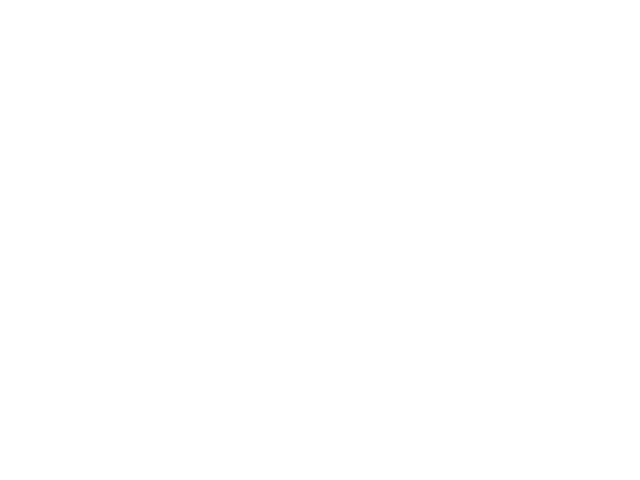

In [7]:
plt.figure()
plt.plot(idx, np.array(alts) - np.array(alpha_cen_alts), 'g-', label='Alt Difference (Pointing - Alpha Cen)')
plt.show()